In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model
from scipy.optimize import minimize
import seaborn as sns

In [32]:
files ={
    "CZK": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Czech_koruna.csv",
    "DKK": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Danish_krone.csv",
    "HUF": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Hungarian_forint.csv",
    "PLN": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Polish_zloty.csv",
    "RON": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Romanian_leu.csv",
    "SEK": "/Users/eddiechiu/Documents/GitHub/Thesis/data/Swedish_krona.csv",
    "USD_EUR": "/Users/eddiechiu/Documents/GitHub/Thesis/data/USD_EUR.csv",
}


In [33]:
def load_data(path, currency):
    df = pd.read_csv(path)
    val_col = [c for c in df.columns if c not in ("DATE", "TIME PERIOD")][0]
    out = df[["DATE", val_col]].copy()
    out.columns = ["date", currency]
    out["date"] = pd.to_datetime(out["date"])
    out[currency] = pd.to_numeric(out[currency], errors="coerce")
    return out.set_index("date").sort_index()

rates = pd.concat([load_data(p, c) for c, p in files.items()], axis=1)

In [34]:
rates = rates.loc["2000-01-01":"2024-12-31"] 
rates = rates.dropna()

In [35]:
print(rates.head())
print(rates.shape)

               CZK     DKK     HUF     PLN     RON     SEK  USD_EUR
date                                                               
2000-01-03  36.063  7.4404  254.53  4.1835  1.8273  8.5520   1.0090
2000-01-04  36.270  7.4429  254.52  4.2423  1.8858  8.6215   1.0305
2000-01-05  36.337  7.4444  254.51  4.2627  1.8979  8.6415   1.0368
2000-01-06  36.243  7.4441  254.45  4.2593  1.9000  8.6445   1.0388
2000-01-07  36.027  7.4436  254.63  4.1897  1.8822  8.6450   1.0284
(6399, 7)


In [36]:
returns = np.log(rates / rates.shift(1)).dropna()


In [37]:
model = arch_model(returns["PLN"] * 100, vol="Garch", p=1, q=1, dist="t")
result = model.fit(disp="off")

print(result.summary())

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                          PLN   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -3610.94
Distribution:      Standardized Student's t   AIC:                           7231.89
Method:                  Maximum Likelihood   BIC:                           7265.71
                                              No. Observations:                 6398
Date:                      Mon, Aug 03 2026   Df Residuals:                     6397
Time:                              20:44:07   Df Model:                            1
                                  Mean Model                                  
                 coef    std err          t      P>|t|        95.0% Conf. Int.
-----------------------------------------------------------------------------

In [38]:
results = {}

for currency in returns.columns:
    model = arch_model(returns[currency] * 100, vol="Garch", p=1, q=1, dist="t", rescale=True)
    results[currency] = model.fit(disp="off")
    print(f"\n=== {currency} ===")
    print(results[currency].summary())


=== CZK ===
                        Constant Mean - GARCH Model Results                         
Dep. Variable:                          CZK   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -386.057
Distribution:      Standardized Student's t   AIC:                           782.114
Method:                  Maximum Likelihood   BIC:                           815.933
                                              No. Observations:                 6398
Date:                      Mon, Aug 03 2026   Df Residuals:                     6397
Time:                              20:44:07   Df Model:                            1
                                   Mean Model                                  
                  coef    std err          t      P>|t|        95.0% Conf. Int.
--------------------------------------------------------------

In [39]:
summary_table = pd.DataFrame({
    currency: {
        "alpha": res.params["alpha[1]"],
        "beta": res.params["beta[1]"],
        "alpha+beta": res.params["alpha[1]"] + res.params["beta[1]"],
        "nu": res.params["nu"],
        "converged": res.convergence_flag == 0,
    }
    for currency, res in results.items()
}).T

print(summary_table)

            alpha      beta alpha+beta         nu converged
CZK           0.1      0.88       0.98   4.315329      True
DKK      0.147353  0.852647        1.0   3.925436      True
HUF      0.075874  0.924126        1.0   6.103975      True
PLN      0.094637  0.905312    0.99995   6.518999      True
RON      0.366475  0.065969   0.432443  87.917981      True
SEK      0.056431  0.934689   0.991119   8.729405      True
USD_EUR  0.030212  0.967869    0.99808   7.627595      True


<Axes: title={'center': 'RON log returns'}, xlabel='date'>

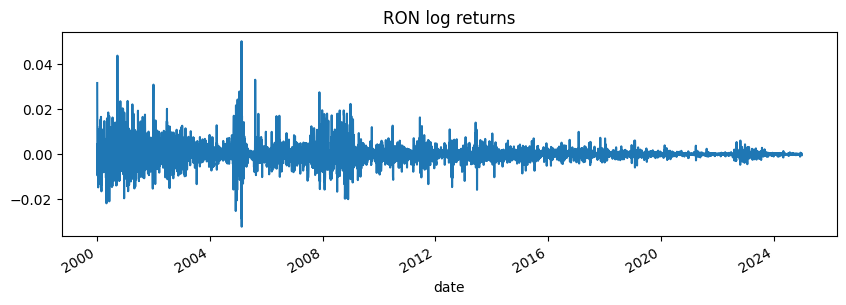

In [40]:
returns["RON"].plot(figsize=(10,3), title="RON log returns")


In [41]:
#new period 
rates_new = rates.loc["2005-01-01":"2025-12-31"] 
rates_new = rates_new.dropna()

returns_new = np.log(rates_new / rates_new.shift(1)).dropna()


In [42]:
results_new = {}

for currency in returns_new.columns:
    model = arch_model(returns_new[currency] * 100, vol="Garch", p=1, q=1, dist="t", rescale=True,)
    results_new[currency] = model.fit(disp="off", options={"maxiter": 30000}) 
    
    print(f"\n=== {currency} ===")
    print(results_new[currency].summary())
    print(results_new[currency].cov_type)

/var/folders/s_/_nfn0dv128bfblp2pcw4b06w0000gn/T/ipykernel_54357/1400764179.py:5: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  results_new[currency] = model.fit(disp="off", options={"maxiter": 30000})



=== CZK ===
                        Constant Mean - GARCH Model Results                         
Dep. Variable:                          CZK   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:                96.8549
Distribution:      Standardized Student's t   AIC:                          -183.710
Method:                  Maximum Likelihood   BIC:                          -151.005
                                              No. Observations:                 5120
Date:                      Mon, Aug 03 2026   Df Residuals:                     5119
Time:                              20:44:08   Df Model:                            1
                                  Mean Model                                  
                  coef    std err          t      P>|t|       95.0% Conf. Int.
----------------------------------------------------------------

In [43]:
summary_table = pd.DataFrame({
    currency: {
        "alpha": res.params["alpha[1]"],
        "beta": res.params["beta[1]"],
        "alpha+beta": res.params["alpha[1]"] + res.params["beta[1]"],
        "nu": res.params["nu"],
        "converged": res.convergence_flag == 0,
    }
    for currency, res in results_new.items()
}).T

print(summary_table)

            alpha      beta alpha+beta        nu converged
CZK      0.200928  0.799398   1.000326  4.399805     False
DKK        0.1544    0.8456        1.0  3.862587      True
HUF      0.069549  0.927968   0.997517  7.769614      True
PLN      0.092802  0.905386   0.998189   6.50813      True
RON      0.198104  0.743607   0.941712  5.266542      True
SEK       0.05047  0.941622   0.992092  8.005661      True
USD_EUR  0.030871  0.966572   0.997443  6.923828      True


<Axes: title={'center': 'PLN log returns'}, xlabel='date'>

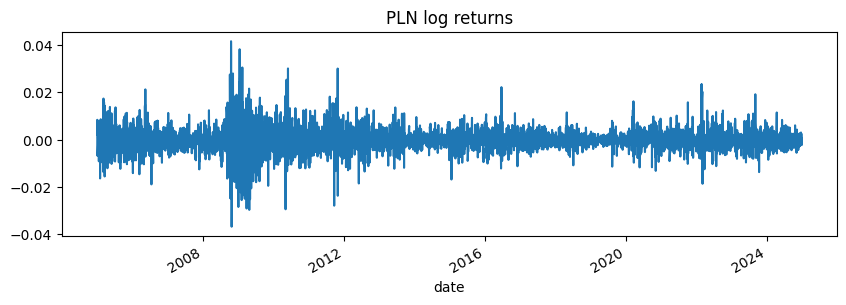

In [44]:
returns_new["PLN"].plot(figsize=(10,3), title="PLN log returns")



In [45]:
#maxiter adjustment dont work
#fix the CZK convergence issue by adjusting the optimization method and maxiter parameter


In [46]:
#standardized residuals
std_resid = {}

for currency, result in results_new.items():
    std_resid[currency] = result.std_resid

std_resid_df = pd.DataFrame(std_resid)
std_resid_df = std_resid_df.dropna()

print(std_resid_df.shape)
print(std_resid_df.head())
print(std_resid_df.isna().sum())

(5120, 7)
                 CZK       DKK       HUF       PLN       RON       SEK  \
date                                                                     
2005-01-04  0.062762 -1.417126 -0.257369  0.403222 -0.684146  3.060602   
2005-01-05  0.752973  2.934256  1.029462  1.632635 -0.721412 -0.065614   
2005-01-06  0.120830  0.173262  2.266968 -0.033662  0.309228 -0.158450   
2005-01-07 -1.811022 -0.051501  0.729242 -1.255276  0.736950 -0.191204   
2005-01-10 -0.635895  0.203102 -0.891687 -0.644558 -1.164021  0.552031   

             USD_EUR  
date                  
2005-01-04 -1.770152  
2005-01-05 -1.720652  
2005-01-06 -0.488585  
2005-01-07  0.206529  
2005-01-10 -1.193756  
CZK        0
DKK        0
HUF        0
PLN        0
RON        0
SEK        0
USD_EUR    0
dtype: int64


In [47]:
print(std_resid_df.index.min(), "→", std_resid_df.index.max())
print("PLN original result count:", len(results["PLN"].std_resid))

2005-01-04 00:00:00 → 2024-12-31 00:00:00
PLN original result count: 6398


In [48]:
# epsilon_t = standardized residuals from each currency's GARCH fit
epsilon = std_resid_df.values   # T x n matrix, rows = time, columns = currencies
T, n = epsilon.shape

# S = unconditional correlation matrix of epsilon_t (paper's S / Q_bar)
S = np.corrcoef(epsilon.T)

def dcc_loglik(params, epsilon, S):
    alpha, beta = params
    if alpha < 0 or beta < 0 or alpha + beta >= 1:
        return 1e10

    T, n = epsilon.shape
    Q_t = S.copy()
    loglik = 0

    for t in range(1, T):
        eps_prev = epsilon[t-1].reshape(-1, 1)

        # Eq. 22: Q_t = (1-alpha-beta)S + alpha * eps_{t-1} eps_{t-1}' + beta * Q_{t-1}
        Q_t = (1 - alpha - beta) * S + alpha * (eps_prev @ eps_prev.T) + beta * Q_t

        # Eq. 23-24: R_t = (I ⊙ Q_t^{1/2})^{-1} Q_t (I ⊙ Q_t^{1/2})^{-1}
        q_diag_sqrt = np.sqrt(np.diag(Q_t))
        R_t = Q_t / np.outer(q_diag_sqrt, q_diag_sqrt)

        eps_t = epsilon[t]
        try:
            R_t_inv = np.linalg.inv(R_t)
            sign, logdet_R_t = np.linalg.slogdet(R_t)
            if sign <= 0:
                return 1e10
            # QML log-likelihood contribution (Eq. 25, Gaussian form)
            loglik += -0.5 * (logdet_R_t + eps_t @ R_t_inv @ eps_t)
        except np.linalg.LinAlgError:
            return 1e10

    return -loglik  # scipy minimizes, so return negative log-likelihood

# Estimate alpha, beta via QML
result = minimize(
    dcc_loglik, x0=[0.05, 0.90],
    args=(epsilon, S), method="Nelder-Mead"
)
alpha_hat, beta_hat = result.x
print("Converged:", result.success)
print("alpha:", alpha_hat, "beta:", beta_hat, "alpha+beta:", alpha_hat + beta_hat)

Converged: True
alpha: 0.007547164560130583 beta: 0.985291373333138 alpha+beta: 0.9928385378932686


In [49]:
#MLE reestimation of DCC parameters a,b
def compute_R_series(epsilon, S, alpha, beta):
    T, n = epsilon.shape
    Q_t = S.copy()
    R_series = np.zeros((T, n, n))

    for t in range(T):
        q_diag_sqrt = np.sqrt(np.diag(Q_t))
        R_t = Q_t / np.outer(q_diag_sqrt, q_diag_sqrt)
        R_series[t] = R_t

        if t < T - 1:
            eps_t = epsilon[t].reshape(-1, 1)
            Q_t = (1 - alpha - beta) * S + alpha * (eps_t @ eps_t.T) + beta * Q_t

    return R_series

R_series = compute_R_series(epsilon, S, alpha_hat, beta_hat)
print(R_series.shape)

(5120, 7, 7)


In [50]:
currencies = std_resid_df.columns.tolist()
n = len(currencies)

pairwise_corr = {}
for i in range(n):
    for j in range(i+1, n):
        pair_name = f"{currencies[i]}_{currencies[j]}"
        pairwise_corr[pair_name] = R_series[:, i, j]

corr_df = pd.DataFrame(pairwise_corr, index=std_resid_df.index)
print(corr_df.head())
print(corr_df.describe())

             CZK_DKK   CZK_HUF   CZK_PLN   CZK_RON   CZK_SEK  CZK_USD_EUR  \
date                                                                        
2005-01-04 -0.007353  0.333825  0.360258  0.138727  0.125182    -0.142860   
2005-01-05 -0.007969  0.333613  0.360223  0.138153  0.122358    -0.142020   
2005-01-06  0.008545  0.337451  0.365131  0.133447  0.121745    -0.149858   
2005-01-07  0.008587  0.333020  0.365043  0.133716  0.121609    -0.150112   
2005-01-10  0.009056  0.318361  0.375451  0.121646  0.122667    -0.150966   

                 DKK_HUF   DKK_PLN   DKK_RON   DKK_SEK  ...   HUF_PLN  \
date                                                    ...             
2005-01-04 -2.589722e-02 -0.012646  0.018856  0.028369  ...  0.560612   
2005-01-05 -2.294331e-02 -0.016853  0.025984 -0.004424  ...  0.559336   
2005-01-06  6.979267e-07  0.018787  0.009539 -0.005437  ...  0.564179   
2005-01-07  2.671092e-03  0.018523  0.009996 -0.005402  ...  0.552803   
2005-01-10  2.194061e-

In [51]:
print(R_series.shape)
print(corr_df.describe())

(5120, 7, 7)
           CZK_DKK      CZK_HUF      CZK_PLN      CZK_RON      CZK_SEK  \
count  5120.000000  5120.000000  5120.000000  5120.000000  5120.000000   
mean     -0.006963     0.334825     0.363188     0.139955     0.127523   
std       0.047244     0.094989     0.095196     0.066175     0.078200   
min      -0.128416    -0.000069     0.079064    -0.080080    -0.131565   
25%      -0.040732     0.266228     0.305237     0.096548     0.082651   
50%      -0.002638     0.339557     0.360427     0.133405     0.122064   
75%       0.024161     0.405636     0.440414     0.179694     0.176867   
max       0.152927     0.551122     0.552615     0.317839     0.338485   

       CZK_USD_EUR      DKK_HUF      DKK_PLN      DKK_RON      DKK_SEK  ...  \
count  5120.000000  5120.000000  5120.000000  5120.000000  5120.000000  ...   
mean     -0.142255    -0.026795    -0.012332     0.018713     0.028380  ...   
std       0.078372     0.040058     0.046467     0.049372     0.048715  ...   
min 

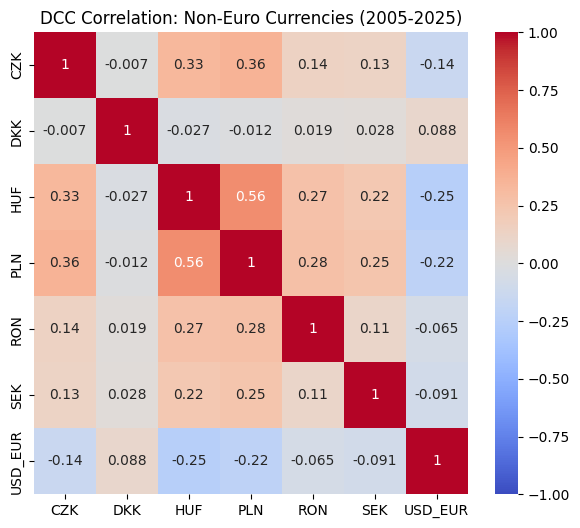

In [52]:
mean_corr = {}
for i in range(len(currencies)):
    for j in range(len(currencies)):
        if i == j:
            mean_corr[(currencies[i], currencies[j])] = 1.0
        else:
            key = f"{currencies[min(i,j)]}_{currencies[max(i,j)]}"
            if key in corr_df.columns:
                mean_corr[(currencies[i], currencies[j])] = corr_df[key].mean()


corr_matrix = pd.DataFrame(index=currencies, columns=currencies, dtype=float)
for (a, b), v in mean_corr.items():
    corr_matrix.loc[a, b] = v

plt.figure(figsize=(7,6))
sns.heatmap(corr_matrix.astype(float), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("DCC Correlation: Non-Euro Currencies (2005-2025)")
plt.show()

(5120, 21)


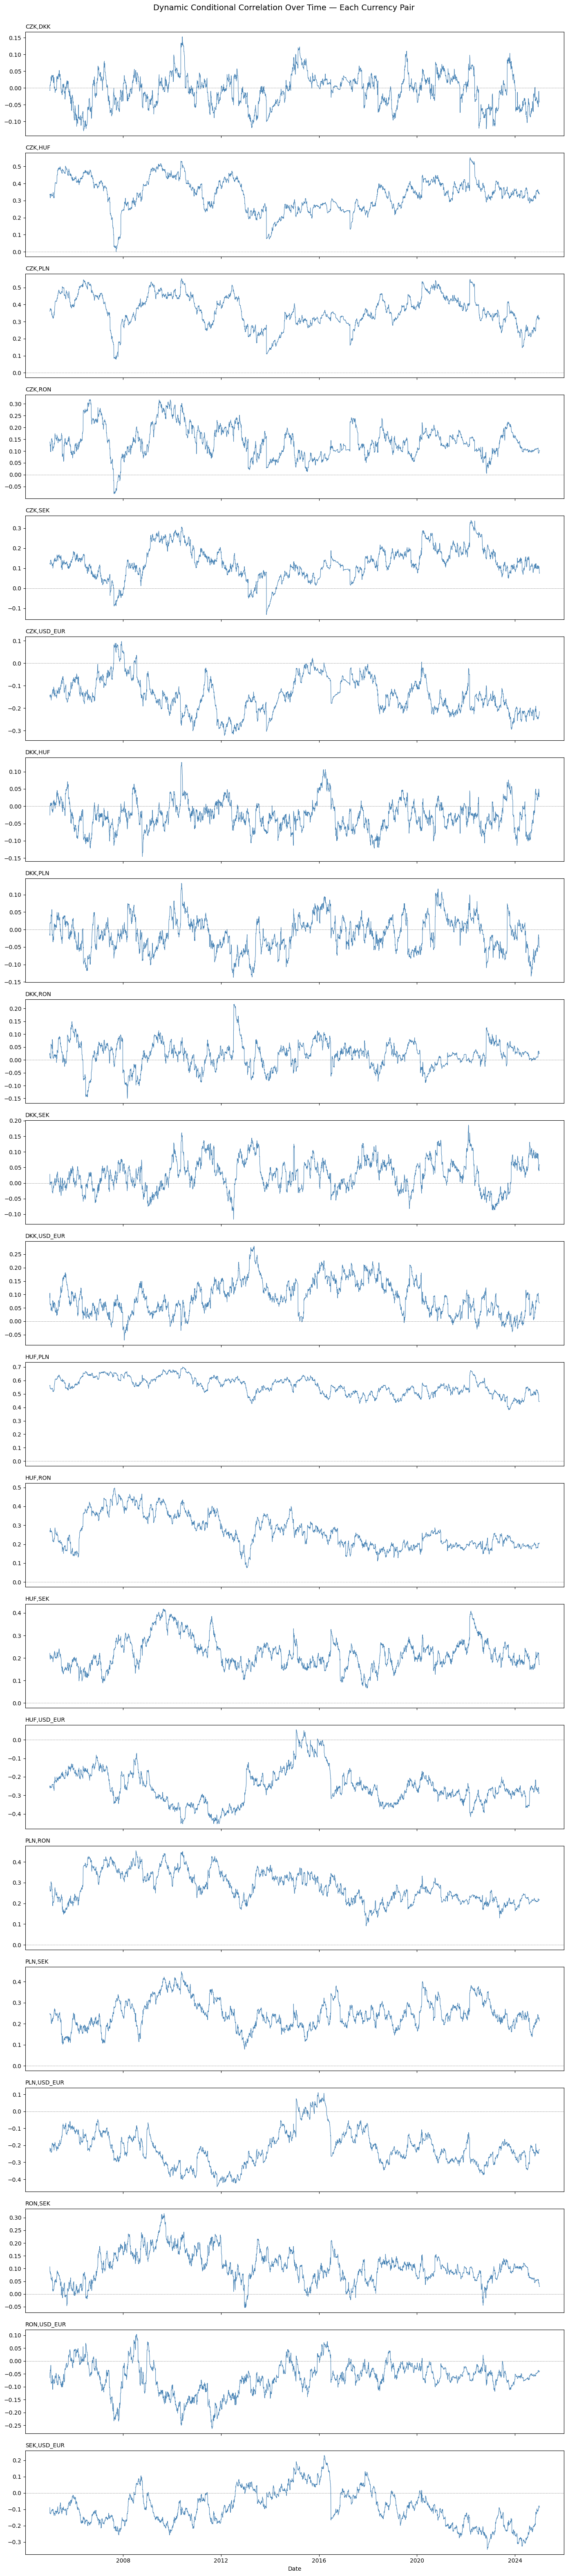

In [53]:
pairwise_series = {}

for i in range(len(currencies)):
    for j in range(i+1, len(currencies)):  # unique pairs only
        key = f"{currencies[i]},{currencies[j]}"
        pairwise_series[key] = R_series[:, i, j]

pairwise_df = pd.DataFrame(pairwise_series, index=std_resid_df.index)
print(pairwise_df.shape)  # (T, 15)

n_pairs = len(pairwise_df.columns)

fig, axes = plt.subplots(
    nrows=n_pairs, ncols=1,
    figsize=(14, 3 * n_pairs),   # scales height with number of pairs
    sharex=True
)

for ax, col in zip(axes, pairwise_df.columns):
    ax.plot(pairwise_df.index, pairwise_df[col], linewidth=0.8, color="steelblue")
    ax.set_title(col, loc="left", fontsize=10)
    ax.axhline(0, color="gray", linewidth=0.5, linestyle="--")
    #ax.set_ylim(-1, 1)

axes[-1].set_xlabel("Date")
fig.suptitle("Dynamic Conditional Correlation Over Time — Each Currency Pair", fontsize=14, y=1.0)
plt.tight_layout()
plt.show()

In [54]:
pairwise_annual = pairwise_df.resample("Y").mean()
print(pairwise_annual.shape)   # should be roughly (20, 15) — 20 years, 15 pairs
print(pairwise_annual.head())

rho_annual = pd.DataFrame(index=pairwise_annual.index)

for ccy in currencies:
    others = [c for c in currencies if c != ccy]
    pair_cols = []
    for o in others:
        key1 = f"{ccy},{o}"
        key2 = f"{o},{ccy}"
        if key1 in pairwise_annual.columns:
            pair_cols.append(key1)
        elif key2 in pairwise_annual.columns:
            pair_cols.append(key2)
    rho_annual[ccy] = pairwise_annual[pair_cols].mean(axis=1)

print(rho_annual)

(20, 21)
             CZK,DKK   CZK,HUF   CZK,PLN   CZK,RON   CZK,SEK  CZK,USD_EUR  \
date                                                                        
2005-12-31  0.002095  0.431383  0.425641  0.129204  0.133363    -0.120335   
2006-12-31 -0.062898  0.431009  0.483012  0.212878  0.112758    -0.119936   
2007-12-31 -0.015667  0.235249  0.283113  0.099061  0.007639    -0.014804   
2008-12-31  0.000529  0.310908  0.354426  0.118871  0.092915    -0.064972   
2009-12-31 -0.010127  0.469779  0.474789  0.247932  0.239416    -0.155216   

             DKK,HUF   DKK,PLN   DKK,RON   DKK,SEK  ...   HUF,PLN   HUF,RON  \
date                                                ...                       
2005-12-31  0.007573  0.009720  0.048231  0.004657  ...  0.572216  0.211119   
2006-12-31 -0.061209 -0.045943 -0.005296 -0.007175  ...  0.622624  0.312587   
2007-12-31 -0.046339 -0.021328  0.047413  0.028509  ...  0.644762  0.417552   
2008-12-31 -0.024656 -0.004198 -0.047950  0.012159  ... 

/var/folders/s_/_nfn0dv128bfblp2pcw4b06w0000gn/T/ipykernel_54357/2401099408.py:1: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  pairwise_annual = pairwise_df.resample("Y").mean()


In [55]:
rho_long = rho_annual.reset_index().melt(id_vars="date", var_name="currency", value_name="rho")
rho_long["year"] = rho_long["date"].dt.year
rho_long = rho_long.drop(columns="date")

print(rho_long.head())
print(rho_long.shape)  # roughly 20 years x 6 currencies = ~120 row

  currency       rho  year
0      CZK  0.166892  2005
1      CZK  0.176137  2006
2      CZK  0.099099  2007
3      CZK  0.135446  2008
4      CZK  0.211095  2009
(140, 3)


In [56]:
#https://ec.europa.eu/eurostat/databrowser/view/nama_10_gdp__custom_22265205/default/table
df = pd.read_csv("/Users/eddiechiu/Documents/GitHub/Thesis/data/nama_10_gdp__custom_22265205_linear_2_0.csv")
print(df.head())
print(df.columns.tolist())

  STRUCTURE            STRUCTURE_ID  \
0  dataflow  ESTAT:NAMA_10_GDP(1.0)   
1  dataflow  ESTAT:NAMA_10_GDP(1.0)   
2  dataflow  ESTAT:NAMA_10_GDP(1.0)   
3  dataflow  ESTAT:NAMA_10_GDP(1.0)   
4  dataflow  ESTAT:NAMA_10_GDP(1.0)   

                                      STRUCTURE_NAME freq Time frequency  \
0  Gross domestic product (GDP) and main componen...    A         Annual   
1  Gross domestic product (GDP) and main componen...    A         Annual   
2  Gross domestic product (GDP) and main componen...    A         Annual   
3  Gross domestic product (GDP) and main componen...    A         Annual   
4  Gross domestic product (GDP) and main componen...    A         Annual   

      unit               Unit of measure na_item  \
0  CP_MEUR  Current prices, million euro    B1GQ   
1  CP_MEUR  Current prices, million euro    B1GQ   
2  CP_MEUR  Current prices, million euro    B1GQ   
3  CP_MEUR  Current prices, million euro    B1GQ   
4  CP_MEUR  Current prices, million euro    B1GQ

In [57]:
gdp_raw = pd.read_csv("/Users/eddiechiu/Documents/GitHub/Thesis/data/nama_10_gdp__custom_22265205_linear_2_0.csv")

gdp = gdp_raw[["geo", "TIME_PERIOD", "OBS_VALUE"]].copy()
gdp.columns = ["country", "year", "gdp_meur"]

# filter to your six countries and your window
your_countries = ["PL", "CZ", "HU", "RO", "SE", "DK"]
gdp = gdp[gdp["country"].isin(your_countries)]
gdp = gdp[(gdp["year"] >= 2005) & (gdp["year"] <= 2025)]

# pivot so each country is a column, year is the index — easy to inspect
gdp_wide = gdp.pivot(index="year", columns="country", values="gdp_meur")
print(gdp_wide)

country        CZ        DK        HU        PL        RO        SE
year                                                               
2005     110418.8  213381.8   90999.5  246903.6   79223.9  315348.4
2006     124559.0  225930.8   92038.0  275514.0   97215.6  336866.7
2007     138897.5  233960.3  102368.2  314356.3  127632.0  358064.8
2008     161852.2  242720.1  108278.8  367420.9  146589.7  352761.6
2009     149253.1  232270.0   94416.6  317876.9  125219.8  313033.6
2010     159506.1  243429.9   99562.8  360890.7  128305.3  372381.5
2011     166545.5  248105.0  101986.9  379540.6  138528.2  410287.8
2012     163759.4  254300.7   99979.9  387660.3  139307.7  427901.2
2013     160470.0  259530.9  102210.9  390177.0  142936.0  439805.4
2014     158991.5  265635.7  106335.3  408714.7  150528.8  435639.5
2015     170527.3  272193.0  112854.0  432485.8  160289.0  452337.2
2016     179145.9  282265.1  116593.5  427658.6  167497.1  463918.8
2017     196738.7  294355.0  127222.5  469071.2 

In [58]:
#https://ec.europa.eu/eurostat/databrowser/view/ds-045409__custom_22289115/default/table
trade_raw = pd.read_csv("/Users/eddiechiu/Documents/GitHub/Thesis/data/ds-045409__custom_22289115_linear_2_0 (1).csv")

print("Shape:", trade_raw.shape)
print("Columns:", trade_raw.columns.tolist())
print(trade_raw.head())

# lowercase 'flow' is the numeric code, uppercase 'FLOW' the text label
print(trade_raw[["flow", "FLOW"]].head(10))
print(trade_raw["flow"].dtype, trade_raw["FLOW"].dtype)
print(trade_raw["flow"].unique())
print(trade_raw["FLOW"].unique())


Shape: (5040, 19)
Columns: ['STRUCTURE', 'STRUCTURE_ID', 'STRUCTURE_NAME', 'freq', 'Frequency', 'reporter', 'REPORTER', 'partner', 'PARTNER', 'product', 'PRODUCT', 'flow', 'FLOW', 'indicators', 'INDICATORS', 'TIME_PERIOD', 'TIME_PERIOD.1', 'OBS_VALUE', 'Observation Value']
  STRUCTURE          STRUCTURE_ID                          STRUCTURE_NAME  \
0  dataflow  ESTAT:DS-045409(1.0)  EU trade since 1988 by HS2-4-6 and CN8   
1  dataflow  ESTAT:DS-045409(1.0)  EU trade since 1988 by HS2-4-6 and CN8   
2  dataflow  ESTAT:DS-045409(1.0)  EU trade since 1988 by HS2-4-6 and CN8   
3  dataflow  ESTAT:DS-045409(1.0)  EU trade since 1988 by HS2-4-6 and CN8   
4  dataflow  ESTAT:DS-045409(1.0)  EU trade since 1988 by HS2-4-6 and CN8   

  freq Frequency reporter REPORTER partner  PARTNER product PRODUCT  flow  \
0    A    Annual       CZ  Czechia      AT  Austria   TOTAL   Total     1   
1    A    Annual       CZ  Czechia      AT  Austria   TOTAL   Total     1   
2    A    Annual       CZ  Czech

In [59]:


# explicitly select uppercase FLOW (the text labels), not lowercase flow (numeric codes)
trade = trade_raw[["reporter", "partner", "TIME_PERIOD", "FLOW", "OBS_VALUE"]].copy()
trade.columns = ["country", "partner", "year", "flow_label", "value"]

print(trade["flow_label"].unique())   # should show ['IMPORT' 'EXPORT']

# filter to your window
trade = trade[(trade["year"] >= 2005) & (trade["year"] <= 2025)]

# split
exports = trade[trade["flow_label"] == "EXPORT"]
imports = trade[trade["flow_label"] == "IMPORT"]

print("exports shape:", exports.shape)
print("imports shape:", imports.shape)

# sum across all 20 Eurozone partners, per reporting country per year
exports_summed = exports.groupby(["country", "year"])["value"].sum().reset_index()
exports_summed.columns = ["country", "year", "exports_to_EA"]

imports_summed = imports.groupby(["country", "year"])["value"].sum().reset_index()
imports_summed.columns = ["country", "year", "imports_from_EA"]

trade_final = exports_summed.merge(imports_summed, on=["country", "year"])
trade_final["trade_volume_EA"] = trade_final["exports_to_EA"] + trade_final["imports_from_EA"]
trade_final["trade_balance_EA"] = trade_final["exports_to_EA"] - trade_final["imports_from_EA"]

trade_final["exports_to_EA_meur"] = trade_final["exports_to_EA"] / 1_000_000
trade_final["imports_from_EA_meur"] = trade_final["imports_from_EA"] / 1_000_000
trade_final["trade_volume_EA_meur"] = trade_final["trade_volume_EA"] / 1_000_000

print(trade_final.head(20))
print(trade_final.shape)
print(trade_final["country"].unique())

['IMPORT' 'EXPORT']
exports shape: (2520, 5)
imports shape: (2520, 5)
   country  year  exports_to_EA  imports_from_EA  trade_volume_EA  \
0       CZ  2005    43629918412      42087254365      85717172777   
1       CZ  2006    51758021403      49435642199     101193663602   
2       CZ  2007    60039793848      56654792423     116694586271   
3       CZ  2008    66551443953      60225865708     126777309661   
4       CZ  2009    55047270237      47726739456     102774009693   
5       CZ  2010    67200197153      57629048339     124829245492   
6       CZ  2011    77688147813      65458144676     143146292489   
7       CZ  2012    78493163072      65830650085     144323813157   
8       CZ  2013    77696195052      65489636239     143185831291   
9       CZ  2014    84245520836      70202634145     154448154981   
10      CZ  2015    92223874059      76002317790     168226191849   
11      CZ  2016    96172620901      77823896064     173996516965   
12      CZ  2017   105638930680  

In [60]:
czk_trade = trade_final[trade_final["country"] == "CZ"]
czk_gdp = gdp_wide["CZ"].reset_index()
czk_gdp.columns = ["year", "gdp_meur"]

check = czk_trade.merge(czk_gdp, on="year")
check["trade_pct_gdp"] = check["trade_volume_EA_meur"] / check["gdp_meur"] * 100
print(check[["year", "trade_volume_EA_meur", "gdp_meur", "trade_pct_gdp"]])

gdp_long = gdp_wide.reset_index().melt(id_vars="year", var_name="country", value_name="gdp_meur")

trade_gdp_check = trade_final.merge(gdp_long, on=["country", "year"])
trade_gdp_check["trade_pct_gdp"] = trade_gdp_check["trade_volume_EA_meur"] / trade_gdp_check["gdp_meur"] * 100

print(trade_gdp_check.groupby("country")["trade_pct_gdp"].describe())

    year  trade_volume_EA_meur  gdp_meur  trade_pct_gdp
0   2005          85717.172777  110418.8      77.629147
1   2006         101193.663602  124559.0      81.241551
2   2007         116694.586271  138897.5      84.014893
3   2008         126777.309661  161852.2      78.329062
4   2009         102774.009693  149253.1      68.858878
5   2010         124829.245492  159506.1      78.259857
6   2011         143146.292489  166545.5      85.950261
7   2012         144323.813157  163759.4      88.131621
8   2013         143185.831291  160470.0      89.229034
9   2014         154448.154981  158991.5      97.142398
10  2015         168226.191849  170527.3      98.650593
11  2016         173996.516965  179145.9      97.125593
12  2017         191309.469661  196738.7      97.240385
13  2018         204085.653281  213505.4      95.588052
14  2019         209182.273255  229406.7      91.184030
15  2020         195795.169493  220310.6      88.872333
16  2021         228889.396735  246012.3      93